<a href="https://colab.research.google.com/github/Samu3lNM/Projects/blob/main/Reconcilliation_Automated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task
Automate the financial reconciliation process for multiple retail stores by matching POS sales records with bank statements using Python. The objective is to identify discrepancies, standardize data formats, and provide a clear visualization of reconciled vs. flagged transactions to improve financial accuracy and operational efficiency.

## Business Understanding & Data Acquisition

### Subtask:
Define reconciliation objectives and generate synthetic retail financial data including POS records and bank statements.


**Reasoning**:
I will generate synthetic POS and Bank data using pandas to simulate a real-world multi-store retail environment. This provides the foundation for the reconciliation logic.



In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Set seed for reproducibility
np.random.seed(42)

# 1. Generate POS Sales Data
num_pos_records = 100
pos_data = {
    'transaction_id': [f'TRX-{1000+i}' for i in range(num_pos_records)],
    'store_id': np.random.choice(['Store_A', 'Store_B', 'Store_C'], num_pos_records),
    'date': [(datetime(2023, 10, 1) + timedelta(days=np.random.randint(0, 5))).strftime('%Y-%m-%d') for _ in range(num_pos_records)],
    'amount': np.round(np.random.uniform(10.0, 500.0, num_pos_records), 2),
    'payment_method': np.random.choice(['Credit Card', 'Debit Card', 'Cash'], num_pos_records)
}
df_pos = pd.DataFrame(pos_data)

# 2. Generate Bank Statement Data
# We will simulate that 'Cash' isn't always deposited immediately, and some transactions might have errors
bank_records = []
for i, row in df_pos.iterrows():
    # Simulate: Skip some records (missing in bank), change some amounts (discrepancy)
    rand_val = np.random.random()
    if row['payment_method'] == 'Cash' and rand_val < 0.4:
        continue # Cash not deposited yet
    if rand_val < 0.05:
        # Amount discrepancy
        bank_records.append([row['date'], f"POS SETTLE {row['transaction_id']}", row['amount'] - 5.0])
    elif rand_val < 0.95:
        # Normal match
        bank_records.append([row['date'], f"POS SETTLE {row['transaction_id']}", row['amount']])

# Add some bank fees that aren't in POS
bank_records.append(['2023-10-03', 'BANK SERVICE FEE', -15.00])

df_bank = pd.DataFrame(bank_records, columns=['bank_date', 'description', 'bank_amount'])

print("POS Data Sample:")
print(df_pos.head())
print("\nBank Data Sample:")
print(df_bank.head())
print(f"\nTotal POS Records: {len(df_pos)}")
print(f"Total Bank Records: {len(df_bank)}")

POS Data Sample:
  transaction_id store_id        date  amount payment_method
0       TRX-1000  Store_C  2023-10-04  320.83    Credit Card
1       TRX-1001  Store_A  2023-10-03  343.55    Credit Card
2       TRX-1002  Store_C  2023-10-03  270.16           Cash
3       TRX-1003  Store_C  2023-10-01  229.41    Credit Card
4       TRX-1004  Store_A  2023-10-03  280.92           Cash

Bank Data Sample:
    bank_date          description  bank_amount
0  2023-10-04  POS SETTLE TRX-1000       320.83
1  2023-10-03  POS SETTLE TRX-1001       343.55
2  2023-10-01  POS SETTLE TRX-1003       229.41
3  2023-10-03  POS SETTLE TRX-1005       300.42
4  2023-10-01  POS SETTLE TRX-1006        49.62

Total POS Records: 100
Total Bank Records: 84


## Data Understanding & Exploratory Analysis

### Subtask:
Explore the structure, summary statistics, and potential inconsistencies in the POS and Bank datasets.


**Reasoning**:
I will start by checking the data types, summary statistics, and missing values for both datasets to ensure they are ready for cleaning and reconciliation.



In [2]:
# 1. Check info and summary statistics
print("--- POS Data Info ---")
print(df_pos.info())
print("\n--- POS Summary Statistics ---")
print(df_pos.describe(include='all'))

print("\n--- Bank Data Info ---")
print(df_bank.info())
print("\n--- Bank Summary Statistics ---")
print(df_bank.describe(include='all'))

# 2. Check for missing values
print("\n--- Missing Values in POS ---")
print(df_pos.isnull().sum())
print("\n--- Missing Values in Bank ---")
print(df_bank.isnull().sum())

# 3. Analyze Store and Payment Method distributions
print("\n--- Transactions per Store ---")
print(df_pos['store_id'].value_counts())
print("\n--- Payment Method Counts ---")
print(df_pos['payment_method'].value_counts())

--- POS Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  100 non-null    object 
 1   store_id        100 non-null    object 
 2   date            100 non-null    object 
 3   amount          100 non-null    float64
 4   payment_method  100 non-null    object 
dtypes: float64(1), object(4)
memory usage: 4.0+ KB
None

--- POS Summary Statistics ---
       transaction_id store_id        date     amount payment_method
count             100      100         100  100.00000            100
unique            100        3           5        NaN              3
top          TRX-1000  Store_B  2023-10-01        NaN     Debit Card
freq                1       36          26        NaN             40
mean              NaN      NaN         NaN  288.58760            NaN
std               NaN      NaN         NaN  133.20742    

## Data Preparation

### Subtask:
Clean the data, standardize date formats, and extract linking keys from the bank descriptions.


**Reasoning**:
Standardizing dates and extracting a common key is essential for joining the datasets in the next subtask.



In [3]:
import re

# 1. Standardize date formats
df_pos['date'] = pd.to_datetime(df_pos['date'])
df_bank['bank_date'] = pd.to_datetime(df_bank['bank_date'])

# 2. Extract transaction_id from Bank description
# We use regex to find 'TRX-XXXX' patterns
def extract_trx_id(desc):
    match = re.search(r'TRX-\d+', desc)
    return match.group(0) if match else None

df_bank['transaction_id'] = df_bank['description'].apply(extract_trx_id)

# 3. Trim whitespace from string columns
df_pos['transaction_id'] = df_pos['transaction_id'].str.strip()
df_pos['store_id'] = df_pos['store_id'].str.strip()

# 4. Verification
print("--- POS Data Types ---")
print(df_pos.dtypes)
print("\n--- Bank Data Types ---")
print(df_bank.dtypes)

print("\nBank Data with Extracted Transaction IDs:")
print(df_bank.head())

--- POS Data Types ---
transaction_id            object
store_id                  object
date              datetime64[ns]
amount                   float64
payment_method            object
dtype: object

--- Bank Data Types ---
bank_date         datetime64[ns]
description               object
bank_amount              float64
transaction_id            object
dtype: object

Bank Data with Extracted Transaction IDs:
   bank_date          description  bank_amount transaction_id
0 2023-10-04  POS SETTLE TRX-1000       320.83       TRX-1000
1 2023-10-03  POS SETTLE TRX-1001       343.55       TRX-1001
2 2023-10-01  POS SETTLE TRX-1003       229.41       TRX-1003
3 2023-10-03  POS SETTLE TRX-1005       300.42       TRX-1005
4 2023-10-01  POS SETTLE TRX-1006        49.62       TRX-1006


## Modeling: Automated Reconciliation Logic

### Subtask:
Develop the core logic to match transactions between POS systems and bank records and flag discrepancies.


**Reasoning**:
I will perform a left join to align POS records with bank data and then identify the discrepancies as per the instructions.



In [4]:
import pandas as pd

# 1. Merge POS data with Bank data
# We use a left join to keep all POS transactions and see what matched in the bank
df_reconciled = pd.merge(df_pos, df_bank[['transaction_id', 'bank_amount', 'bank_date']], on='transaction_id', how='left')

# 2. Define logic to categorize status
def categorize_transaction(row):
    if pd.isnull(row['bank_amount']):
        return 'Missing in Bank'
    elif row['amount'] == row['bank_amount']:
        return 'Matched'
    else:
        return 'Amount Discrepancy'

df_reconciled['status'] = df_reconciled.apply(categorize_transaction, axis=1)

# 3. Identify Unrecognized Bank Entries (Bank records not in POS)
unrecognized_bank = df_bank[~df_bank['transaction_id'].isin(df_pos['transaction_id'])].copy()
unrecognized_bank['status'] = 'Unrecognized Bank Entry'

# 4. Display results
print("--- Reconciliation Status Counts ---")
print(df_reconciled['status'].value_counts())

print("\n--- Sample of Discrepancies (Amount Mismatch or Missing) ---")
print(df_reconciled[df_reconciled['status'] != 'Matched'].head())

print("\n--- Unrecognized Bank Entries ---")
print(unrecognized_bank)

--- Reconciliation Status Counts ---
status
Matched               79
Missing in Bank       17
Amount Discrepancy     4
Name: count, dtype: int64

--- Sample of Discrepancies (Amount Mismatch or Missing) ---
   transaction_id store_id       date  amount payment_method  bank_amount  \
2        TRX-1002  Store_C 2023-10-03  270.16           Cash          NaN   
4        TRX-1004  Store_A 2023-10-03  280.92           Cash          NaN   
11       TRX-1011  Store_C 2023-10-01  491.88           Cash          NaN   
14       TRX-1014  Store_B 2023-10-04  401.19           Cash          NaN   
16       TRX-1016  Store_B 2023-10-01  259.02           Cash          NaN   

   bank_date           status  
2        NaT  Missing in Bank  
4        NaT  Missing in Bank  
11       NaT  Missing in Bank  
14       NaT  Missing in Bank  
16       NaT  Missing in Bank  

--- Unrecognized Bank Entries ---
    bank_date       description  bank_amount transaction_id  \
83 2023-10-03  BANK SERVICE FEE        -

## Evaluation: Validation & Visualization

### Subtask:
Validate the reconciliation results and create visual representations of the matched vs. flagged transactions across different stores.


**Reasoning**:
I will start by aggregating the reconciliation data by store and status, then use seaborn and matplotlib to create the required visualizations.



<Figure size 1000x600 with 0 Axes>

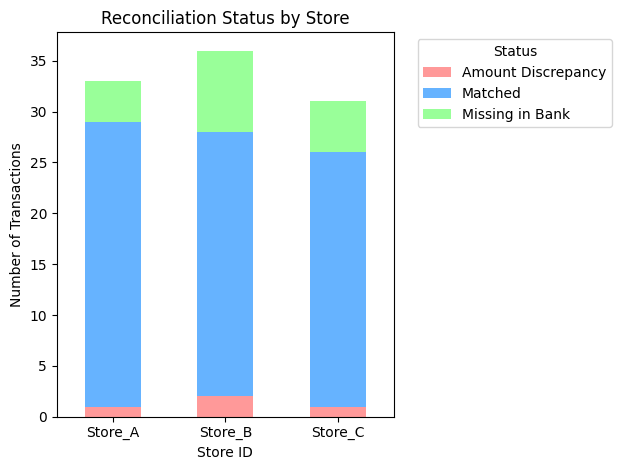

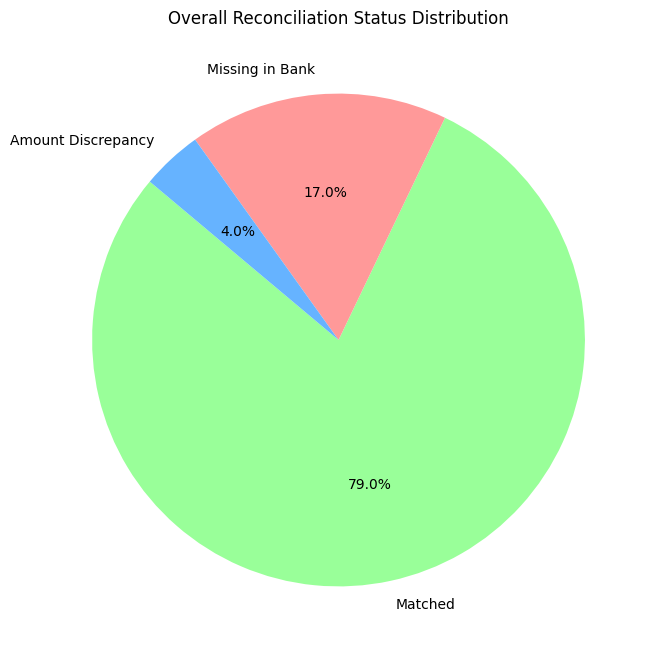

Summary Table by Store:
status    Amount Discrepancy  Matched  Missing in Bank
store_id                                              
Store_A                    1       28                4
Store_B                    2       26                8
Store_C                    1       25                5


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare summary data for visualization
summary_df = df_reconciled.groupby(['store_id', 'status']).size().unstack(fill_value=0)

# 2. Plot Stacked Bar Chart for Stores
plt.figure(figsize=(10, 6))
summary_df.plot(kind='bar', stacked=True, color=['#ff9999','#66b3ff','#99ff99'])
plt.title('Reconciliation Status by Store')
plt.xlabel('Store ID')
plt.ylabel('Number of Transactions')
plt.legend(title='Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Plot Overall Status Distribution (Pie Chart)
status_counts = df_reconciled['status'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=140, colors=['#99ff99','#ff9999','#66b3ff'])
plt.title('Overall Reconciliation Status Distribution')
plt.show()

print("Summary Table by Store:")
print(summary_df)

## Deployment: Final Automation Summary

### Subtask:
Provide a comprehensive final summary of the reconciliation automation project.
